In [1]:
import pandas as pd
import numpy as np
from google.colab import files

uploaded = files.upload()

Saving dirty_cafe_sales.csv to dirty_cafe_sales.csv


In [2]:

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Original Dataset:")
display(df.head())

print("Dataset Shape:", df.shape)

Original Dataset:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


Dataset Shape: (10000, 8)


In [3]:

df.columns = df.columns.str.strip()

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

missing_values = [
    '', 'NULL', 'null', 'N/A', 'NA',
    'UNKNOWN', 'ERROR', 'None'
]

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].replace(missing_values, np.nan)

print("Text cleaning completed!")


Text cleaning completed!


In [4]:

df['Item'] = df['Item'].fillna('Unknown')

df['Item'] = df['Item'].str.title()

print(df['Item'].value_counts(dropna=False))


Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
Unknown      969
Name: count, dtype: int64


In [5]:

numeric_columns = [
    'Quantity',
    'Price Per Unit',
    'Total Spent'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.loc[df['Quantity'] <= 0, 'Quantity'] = np.nan

df.loc[df['Price Per Unit'] < 0, 'Price Per Unit'] = np.nan
df.loc[df['Total Spent'] < 0, 'Total Spent'] = np.nan

df['Quantity'] = df['Quantity'].astype('Int64')

print(df[numeric_columns].dtypes)


Quantity            Int64
Price Per Unit    float64
Total Spent       float64
dtype: object


In [6]:

calculated_total = (
    df['Quantity'] * df['Price Per Unit']
).round(2)

df['Total Spent'] = df['Total Spent'].fillna(calculated_total)

print("Missing Total Spend:",
      df['Total Spent'].isna().sum())


Missing Total Spend: 40


In [7]:

df['Payment Method'] = (
    df['Payment Method'].fillna('Unknown')
)

df['Location'] = (
    df['Location'].fillna('Unknown')
)

df['Payment Method'] = df['Payment Method'].str.title()
df['Location'] = df['Location'].str.title()

print("Payment Methods:")
print(df['Payment Method'].value_counts())

print("\nLocations:")
print(df['Location'].value_counts())


Payment Methods:
Payment Method
Unknown           3178
Digital Wallet    2291
Credit Card       2273
Cash              2258
Name: count, dtype: int64

Locations:
Location
Unknown     3961
Takeaway    3022
In-Store    3017
Name: count, dtype: int64


In [8]:

df['Transaction Date'] = pd.to_datetime(
    df['Transaction Date'],
    errors='coerce'
)

print("Date Data Type:",
      df['Transaction Date'].dtype)

print("Invalid Dates:",
      df['Transaction Date'].isna().sum())


Date Data Type: datetime64[ns]
Invalid Dates: 460


In [9]:

print("Duplicate Transaction IDs:",
      df['Transaction ID'].duplicated().sum())

df = df.drop_duplicates(
    subset=['Transaction ID'],
    keep='first'
)

df = df.drop_duplicates()

print("Duplicates removed!")


Duplicate Transaction IDs: 0
Duplicates removed!


In [10]:

print("Missing Values After Cleaning:")
display(df.isnull().sum().to_frame(
    name='Missing Values'
))

print("\nFinal Data Types:")
print(df.dtypes)

print("\nFinal Dataset Information:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("Duplicate IDs:",
      df['Transaction ID'].duplicated().sum())

display(df.head(20))


Missing Values After Cleaning:


,Missing Values
Transaction ID,0
Item,0
Quantity,479
Price Per Unit,533
Total Spent,40
Payment Method,0
Location,0
Transaction Date,460



Final Data Types:
Transaction ID              object
Item                        object
Quantity                     Int64
Price Per Unit             float64
Total Spent                Float64
Payment Method              object
Location                    object
Transaction Date    datetime64[ns]
dtype: object

Final Dataset Information:
Rows: 10000
Columns: 8
Duplicate IDs: 0


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-Store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,4.0,Credit Card,In-Store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,Unknown,Unknown,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-Store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,Unknown,2023-03-31
6,TXN_4433211,Unknown,3,3.0,9.0,Unknown,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,Unknown,2023-10-28
8,TXN_4717867,Unknown,5,3.0,15.0,Unknown,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,Unknown,In-Store,2023-12-31


In [12]:

print("Missing Quantity Records:")
display(df[df['Quantity'].isna()].head(10))

print("Missing Price Records:")
display(df[df['Price Per Unit'].isna()])

print("Missing Total Spent Records:")
display(df[df['Total Spent'].isna()])

print("Missing Date Records:")
display(df[df['Transaction Date'].isna()])


Missing Quantity Records:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
20,TXN_3522028,Smoothie,<NA>,4.0,20.0,Cash,In-Store,2023-04-04
55,TXN_5522862,Cookie,<NA>,1.0,2.0,Credit Card,Takeaway,2023-03-19
57,TXN_2080895,Cake,<NA>,3.0,3.0,Digital Wallet,In-Store,2023-04-19
66,TXN_8501819,Juice,<NA>,3.0,6.0,Cash,Unknown,2023-03-30
117,TXN_2148617,Juice,<NA>,3.0,9.0,Digital Wallet,Unknown,2023-01-10
153,TXN_6541415,Unknown,<NA>,3.0,12.0,Cash,In-Store,2023-11-25
177,TXN_1896955,Salad,<NA>,5.0,25.0,Unknown,In-Store,2023-09-23
178,TXN_5075974,Smoothie,<NA>,4.0,16.0,Digital Wallet,Unknown,2023-04-11
189,TXN_2643815,Cookie,<NA>,1.0,3.0,Unknown,Unknown,2023-12-06
198,TXN_9788956,Juice,<NA>,3.0,12.0,Unknown,Unknown,2023-04-11


Missing Price Records:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
56,TXN_3578141,Cake,5,NaN,15.0,Unknown,Takeaway,2023-06-27
65,TXN_4987129,Sandwich,3,NaN,<NA>,Unknown,In-Store,2023-10-20
68,TXN_8427104,Salad,2,NaN,10.0,Unknown,In-Store,2023-10-27
85,TXN_8035512,Tea,3,NaN,4.5,Cash,Unknown,2023-10-29
104,TXN_7447872,Juice,2,NaN,6.0,Unknown,Unknown,NaT
...,...,...,...,...,...,...,...,...
9924,TXN_5981429,Juice,2,NaN,6.0,Digital Wallet,Unknown,2023-12-24
9926,TXN_2464706,Cake,4,NaN,12.0,Digital Wallet,Takeaway,2023-11-09
9961,TXN_2153100,Tea,2,NaN,3.0,Cash,Unknown,2023-12-29
9996,TXN_9659401,Unknown,3,NaN,3.0,Digital Wallet,Unknown,2023-06-02


Missing Total Spent Records:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
65,TXN_4987129,Sandwich,3,NaN,<NA>,Unknown,In-Store,2023-10-20
236,TXN_8562645,Salad,<NA>,5.0,<NA>,Unknown,In-Store,2023-05-18
278,TXN_3229409,Juice,<NA>,3.0,<NA>,Cash,Takeaway,2023-04-15
641,TXN_2962976,Juice,<NA>,3.0,<NA>,Unknown,Unknown,2023-03-17
738,TXN_8696094,Sandwich,<NA>,4.0,<NA>,Unknown,Takeaway,2023-05-14
1674,TXN_9367492,Tea,2,NaN,<NA>,Cash,In-Store,2023-06-19
1761,TXN_3611851,Unknown,4,NaN,<NA>,Credit Card,Unknown,2023-02-09
2229,TXN_8498613,Sandwich,2,NaN,<NA>,Unknown,Unknown,2023-11-08
2289,TXN_7524977,Unknown,4,NaN,<NA>,Unknown,Unknown,2023-12-09
2585,TXN_1259340,Tea,3,NaN,<NA>,Digital Wallet,Unknown,2023-02-24


Missing Date Records:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
11,TXN_3051279,Sandwich,2,4.0,8.0,Credit Card,Takeaway,NaT
29,TXN_7640952,Cake,4,3.0,12.0,Digital Wallet,Takeaway,NaT
33,TXN_7710508,Unknown,5,1.0,5.0,Cash,Unknown,NaT
77,TXN_2091733,Salad,1,5.0,5.0,Unknown,In-Store,NaT
103,TXN_7028009,Cake,4,3.0,12.0,Unknown,Takeaway,NaT
...,...,...,...,...,...,...,...,...
9933,TXN_9460419,Cake,1,3.0,3.0,Unknown,Takeaway,NaT
9937,TXN_8253472,Cake,1,3.0,3.0,Unknown,Unknown,NaT
9949,TXN_3130865,Juice,3,3.0,9.0,Unknown,In-Store,NaT
9983,TXN_9226047,Smoothie,3,4.0,12.0,Cash,Unknown,NaT


In [13]:

price_check = df.groupby('Item')['Price Per Unit'].nunique()

print("Number of unique prices per item:")
display(price_check)

valid_items = price_check[
    (price_check == 1) & (price_check.index != 'Unknown')
].index

price_mapping = (
    df[df['Item'].isin(valid_items)]
    .groupby('Item')['Price Per Unit']
    .first()
    .to_dict()
)

df['Price Per Unit'] = df['Price Per Unit'].fillna(
    df['Item'].map(price_mapping)
)

print("Remaining missing prices:",
      df['Price Per Unit'].isna().sum())


Number of unique prices per item:


,Price Per Unit
Item,
Cake,1
Coffee,1
Cookie,1
Juice,1
Salad,1
Sandwich,1
Smoothie,1
Tea,1
Unknown,6


Remaining missing prices: 54


In [14]:

calculated_total = (
    df['Quantity'] * df['Price Per Unit']
).round(2)

df['Total Spent'] = df['Total Spent'].fillna(
    calculated_total
)

print("Remaining missing Total Spent:",
      df['Total Spent'].isna().sum())


Remaining missing Total Spent: 23


In [15]:

remaining_prices = df[df['Price Per Unit'].isna()]

print("Remaining missing price records:")
display(remaining_prices)

print("\nItem distribution:")
print(remaining_prices['Item'].value_counts(dropna=False))


Remaining missing price records:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
118,TXN_4633784,Unknown,5,NaN,15.0,Unknown,In-Store,2023-02-06
151,TXN_4031509,Unknown,4,NaN,16.0,Credit Card,Takeaway,2023-01-04
289,TXN_3495950,Unknown,4,NaN,6.0,Credit Card,In-Store,2023-02-19
334,TXN_2523298,Unknown,4,NaN,6.0,Unknown,In-Store,2023-03-25
550,TXN_4186681,Unknown,4,NaN,6.0,Digital Wallet,Unknown,2023-05-24
750,TXN_5787508,Unknown,3,NaN,9.0,Credit Card,Takeaway,2023-07-23
818,TXN_7940202,Unknown,1,NaN,4.0,Digital Wallet,Unknown,2023-07-23
1154,TXN_2473090,Unknown,2,NaN,3.0,Credit Card,In-Store,2023-03-03
1337,TXN_5031214,Unknown,5,NaN,5.0,Unknown,Takeaway,2023-07-29
1377,TXN_8396271,Unknown,2,NaN,2.0,Unknown,Unknown,2023-09-12



Item distribution:
Item
Unknown    54
Name: count, dtype: int64


In [16]:

# Calculate Total Spent wherever both values are available
calculated_total = (
    df['Quantity'] * df['Price Per Unit']
).round(2)

# Fill remaining missing totals
df['Total Spent'] = df['Total Spent'].fillna(
    calculated_total
)

print("Missing Total Spent:",
      df['Total Spent'].isna().sum())

print("Missing Quantity:",
      df['Quantity'].isna().sum())

print("Missing Price:",
      df['Price Per Unit'].isna().sum())


Missing Total Spent: 23
Missing Quantity: 479
Missing Price: 54


In [17]:
# STEP 1: Recover missing Quantity
# Quantity = Total Spent / Price Per Unit

mask = (
    df['Quantity'].isna() &
    df['Total Spent'].notna() &
    df['Price Per Unit'].notna() &
    (df['Price Per Unit'] > 0)
)

calculated_qty = (
    df.loc[mask, 'Total Spent'] /
    df.loc[mask, 'Price Per Unit']
)

# Only accept positive whole-number quantities
valid_qty = (
    (calculated_qty > 0) &
    np.isclose(calculated_qty, np.round(calculated_qty))
)

qty_indices = calculated_qty.index[valid_qty]

df.loc[qty_indices, 'Quantity'] = (
    np.round(calculated_qty.loc[qty_indices])
)

# STEP 2: Recover missing Price Per Unit
# Price = Total Spent / Quantity

mask = (
    df['Price Per Unit'].isna() &
    df['Total Spent'].notna() &
    df['Quantity'].notna() &
    (df['Quantity'] > 0)
)

calculated_price = (
    df.loc[mask, 'Total Spent'] /
    df.loc[mask, 'Quantity']
)

# Accept positive calculated prices
valid_price = calculated_price > 0

price_indices = calculated_price.index[valid_price]

df.loc[price_indices, 'Price Per Unit'] = (
    calculated_price.loc[price_indices].round(2)
)

# STEP 3: Recover missing Total Spent
# Total Spent = Quantity * Price Per Unit

mask = (
    df['Total Spent'].isna() &
    df['Quantity'].notna() &
    df['Price Per Unit'].notna()
)

df.loc[mask, 'Total Spent'] = (
    df.loc[mask, 'Quantity'] *
    df.loc[mask, 'Price Per Unit']
)

# STEP 4: Set Quantity back to integer type
df['Quantity'] = df['Quantity'].astype('Int64')

# STEP 5: Display remaining missing values
print("Remaining Missing Values:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nUpdated Dataset Shape:")
print(df.shape)


Remaining Missing Values:
Transaction ID        0
Item                  0
Quantity             23
Price Per Unit        6
Total Spent          23
Payment Method        0
Location              0
Transaction Date    460
dtype: int64

Total missing values:
512

Updated Dataset Shape:
(10000, 8)


In [18]:

print("Remaining Missing Quantity:",
      df['Quantity'].isna().sum())

print("Remaining Missing Price:",
      df['Price Per Unit'].isna().sum())

print("Remaining Missing Total Spent:",
      df['Total Spent'].isna().sum())

print("\nRemaining Missing Records:")
display(
    df[
        df[['Quantity', 'Price Per Unit', 'Total Spent']]
        .isna().any(axis=1)
    ]
)


Remaining Missing Quantity: 23
Remaining Missing Price: 6
Remaining Missing Total Spent: 23

Remaining Missing Records:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
236,TXN_8562645,Salad,<NA>,5.0,<NA>,Unknown,In-Store,2023-05-18
278,TXN_3229409,Juice,<NA>,3.0,<NA>,Cash,Takeaway,2023-04-15
641,TXN_2962976,Juice,<NA>,3.0,<NA>,Unknown,Unknown,2023-03-17
738,TXN_8696094,Sandwich,<NA>,4.0,<NA>,Unknown,Takeaway,2023-05-14
1761,TXN_3611851,Unknown,4,NaN,<NA>,Credit Card,Unknown,2023-02-09
2289,TXN_7524977,Unknown,4,NaN,<NA>,Unknown,Unknown,2023-12-09
2796,TXN_9188692,Cake,<NA>,3.0,<NA>,Credit Card,Unknown,2023-12-01
3203,TXN_4565754,Smoothie,<NA>,4.0,<NA>,Digital Wallet,Takeaway,2023-10-06
3224,TXN_6297232,Coffee,<NA>,2.0,<NA>,Unknown,Unknown,2023-04-07
3401,TXN_3251829,Tea,<NA>,1.5,<NA>,Digital Wallet,In-Store,2023-07-25


In [21]:


before_deletion = len(df)

df = df.drop(
    df[
        df['Quantity'].isna() &
        df['Price Per Unit'].isna()
    ].index
).copy()

deleted_rows = before_deletion - len(df)

print("Rows deleted:", deleted_rows)


df['Quantity'] = df['Quantity'].fillna(1)


df['Price Per Unit'] = df['Price Per Unit'].fillna(1)


df['Transaction Date'] = df['Transaction Date'].fillna(
    pd.Timestamp('2023-01-01')
)


mask = df['Total Spent'].isna()

df.loc[mask, 'Total Spent'] = (
    df.loc[mask, 'Quantity'] *
    df.loc[mask, 'Price Per Unit']
)


df['Quantity'] = df['Quantity'].astype('Int64')


print("\nRemaining Missing Values:")
print(df.isnull().sum())

print("\nFinal Dataset Shape:", df.shape)

display(df.head(20))


Rows deleted: 0

Remaining Missing Values:
Transaction ID      0
Item                0
Quantity            0
Price Per Unit      0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
dtype: int64

Final Dataset Shape: (9997, 8)


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-Store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,4.0,Credit Card,In-Store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,Unknown,Unknown,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-Store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,Unknown,2023-03-31
6,TXN_4433211,Unknown,3,3.0,9.0,Unknown,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,Unknown,2023-10-28
8,TXN_4717867,Unknown,5,3.0,15.0,Unknown,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,Unknown,In-Store,2023-12-31


In [22]:

# Delete the 3 records where both Quantity and Price were originally missing

delete_ids = [
    'TXN_7376255',
    'TXN_1082717',
    'TXN_1208561'
]

df = df[~df['Transaction ID'].isin(delete_ids)].copy()

print("Final Dataset Shape:", df.shape)
print("\nRemaining Missing Values:")
print(df.isnull().sum())


Final Dataset Shape: (9997, 8)

Remaining Missing Values:
Transaction ID      0
Item                0
Quantity            0
Price Per Unit      0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
dtype: int64


In [23]:

# Check whether Total Spent matches Quantity * Price Per Unit

df['Calculated Total'] = (
    df['Quantity'] * df['Price Per Unit']
)

df['Mismatch'] = ~np.isclose(
    df['Total Spent'].astype(float),
    df['Calculated Total'].astype(float),
    atol=0.01
)

print("Transactions with mismatched totals:",
      df['Mismatch'].sum())

display(
    df[df['Mismatch']][
        ['Transaction ID', 'Item', 'Quantity',
         'Price Per Unit', 'Total Spent',
         'Calculated Total']
    ].head(20)
)

# Remove temporary checking columns
df.drop(columns=['Calculated Total', 'Mismatch'], inplace=True)


Transactions with mismatched totals: 0


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Calculated Total


In [24]:
print("Current rows:", len(df))

print("Duplicate Transaction IDs:",
      df['Transaction ID'].duplicated().sum())

print("Duplicate complete rows:",
      df.duplicated().sum())

Current rows: 9997
Duplicate Transaction IDs: 0
Duplicate complete rows: 0


In [25]:
df.drop_duplicates(subset=['Transaction ID'], inplace=True)

In [26]:
original_df = pd.read_csv('/content/dirty_cafe_sales.csv')

print("Original rows:", len(original_df))
print("Current rows:", len(df))

# Find transaction IDs that exist in the original
# but are missing from the cleaned dataset

missing_ids = original_df[
    ~original_df['Transaction ID'].isin(df['Transaction ID'])
]

print("\nRecords missing from cleaned dataset:")
display(missing_ids)

print("\nNumber of missing records:", len(missing_ids))

Original rows: 10000
Current rows: 9997

Records missing from cleaned dataset:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
3779,TXN_7376255,UNKNOWN,UNKNOWN,UNKNOWN,25.0,NaN,In-store,2023-05-27
7597,TXN_1082717,ERROR,UNKNOWN,NaN,9.0,Digital Wallet,In-store,2023-12-13
9819,TXN_1208561,NaN,ERROR,NaN,20.0,Credit Card,NaN,2023-08-19



Number of missing records: 3


In [27]:
print(
    original_df[
        original_df['Transaction ID'].isin(
            ['TXN_7376255', 'TXN_1082717', 'TXN_1208561']
        )
    ]['Transaction ID'].value_counts()
)

Transaction ID
TXN_7376255    1
TXN_1082717    1
TXN_1208561    1
Name: count, dtype: int64


In [28]:

# STEP 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set chart appearance
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

print("Libraries imported successfully!")


Libraries imported successfully!


In [29]:

# STEP 2: Dataset overview

print("DATASET OVERVIEW")
print("-" * 40)

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe(include='all'))

print("\nFirst 5 Records:")
display(df.head())


DATASET OVERVIEW
----------------------------------------
Number of Rows: 9997
Number of Columns: 8

Column Names:
['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date']

Data Types:
Transaction ID              object
Item                        object
Quantity                     Int64
Price Per Unit             float64
Total Spent                Float64
Payment Method              object
Location                    object
Transaction Date    datetime64[ns]
dtype: object

Statistical Summary:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,9997,9997,9997.0,9997.000000,9997.0,9997,9997,9997
unique,9997,9,<NA>,NaN,<NA>,4,3,NaN
top,TXN_1961373,Juice,<NA>,NaN,<NA>,Unknown,Unknown,NaN
freq,1,1171,<NA>,NaN,<NA>,3177,3960,NaN
mean,NaN,NaN,3.020906,2.946434,8.913824,NaN,NaN,2023-06-23 13:38:35.854756352
min,NaN,NaN,1.0,1.000000,1.0,NaN,NaN,2023-01-01 00:00:00
25%,NaN,NaN,2.0,2.000000,4.0,NaN,NaN,2023-03-19 00:00:00
50%,NaN,NaN,3.0,3.000000,8.0,NaN,NaN,2023-06-24 00:00:00
75%,NaN,NaN,4.0,4.000000,12.0,NaN,NaN,2023-09-27 00:00:00
max,NaN,NaN,5.0,5.000000,25.0,NaN,NaN,2023-12-31 00:00:00



First 5 Records:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-Store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,4.0,Credit Card,In-Store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,Unknown,Unknown,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-Store,2023-06-11


In [30]:

# STEP 3: Key Performance Indicators (KPIs)

total_revenue = df['Total Spent'].sum()

total_transactions = df['Transaction ID'].nunique()

total_quantity_sold = df['Quantity'].sum()

average_transaction_value = (
    total_revenue / total_transactions
)

average_quantity = df['Quantity'].mean()

print("CAFE SALES PERFORMANCE")
print("=" * 40)

print(f"Total Revenue: {total_revenue:.2f}")
print(f"Total Transactions: {total_transactions}")
print(f"Total Items Sold: {total_quantity_sold}")
print(f"Average Transaction Value: {average_transaction_value:.2f}")
print(f"Average Quantity per Transaction: {average_quantity:.2f}")


CAFE SALES PERFORMANCE
Total Revenue: 89111.50
Total Transactions: 9997
Total Items Sold: 30200
Average Transaction Value: 8.91
Average Quantity per Transaction: 3.02


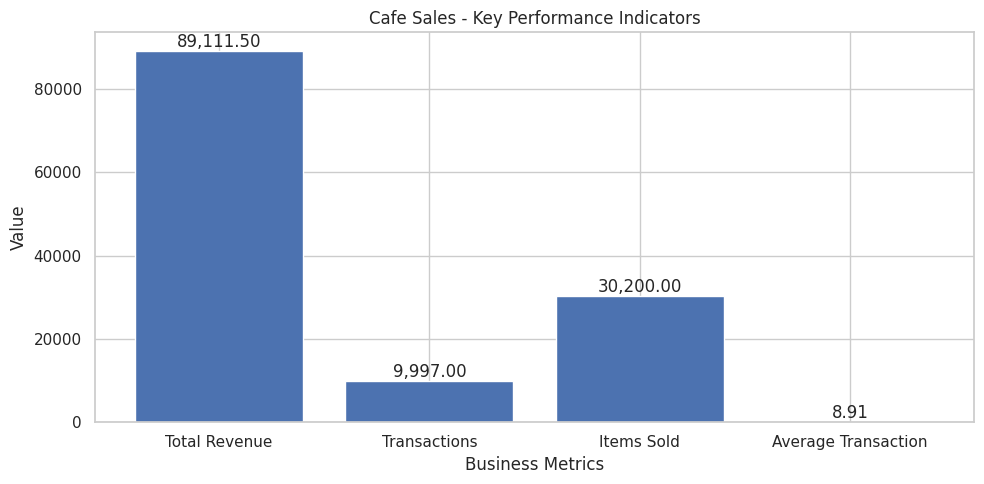

In [31]:

# STEP 4: KPI visualisation

kpi_names = [
    'Total Revenue',
    'Transactions',
    'Items Sold',
    'Average Transaction'
]

kpi_values = [
    total_revenue,
    total_transactions,
    total_quantity_sold,
    average_transaction_value
]

plt.figure(figsize=(10, 5))

bars = plt.bar(kpi_names, kpi_values)

plt.title('Cafe Sales - Key Performance Indicators')
plt.ylabel('Value')
plt.xlabel('Business Metrics')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f'{bar.get_height():,.2f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


PRODUCTS RANKED BY QUANTITY SOLD


,Quantity
Item,
Coffee,3541
Juice,3508
Salad,3471
Cake,3469
Sandwich,3433
Smoothie,3338
Tea,3308
Cookie,3234
Unknown,2898


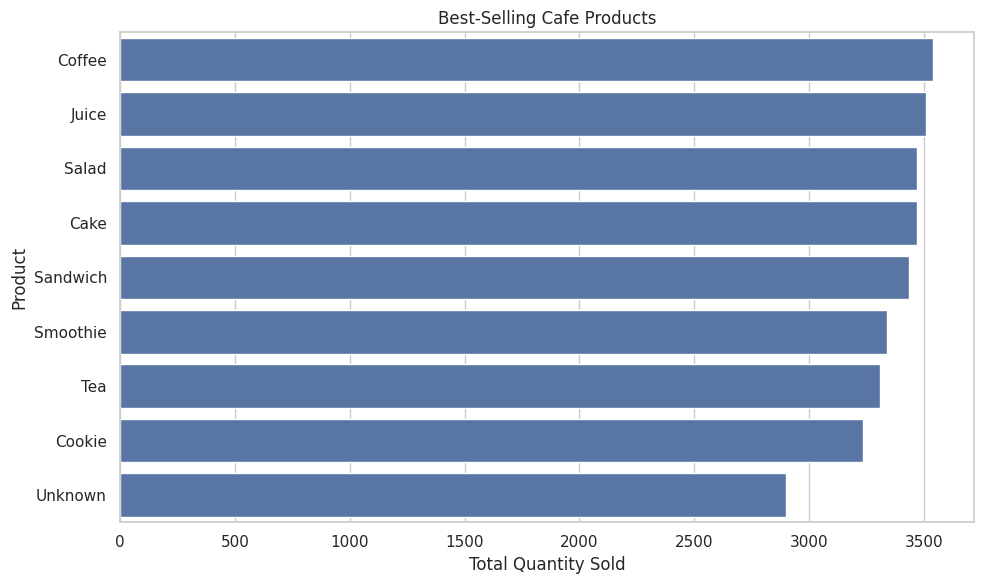

In [32]:

# STEP 5: Product quantity analysis

product_sales = (
    df.groupby('Item')['Quantity']
    .sum()
    .sort_values(ascending=False)
)

print("PRODUCTS RANKED BY QUANTITY SOLD")
display(product_sales)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=product_sales.values,
    y=product_sales.index
)

plt.title('Best-Selling Cafe Products')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product')

plt.tight_layout()
plt.show()


REVENUE BY PRODUCT


,Total Spent
Item,
Salad,17355.0
Sandwich,13732.0
Smoothie,13352.0
Juice,10524.0
Cake,10407.0
Unknown,8463.5
Coffee,7082.0
Tea,4962.0
Cookie,3234.0


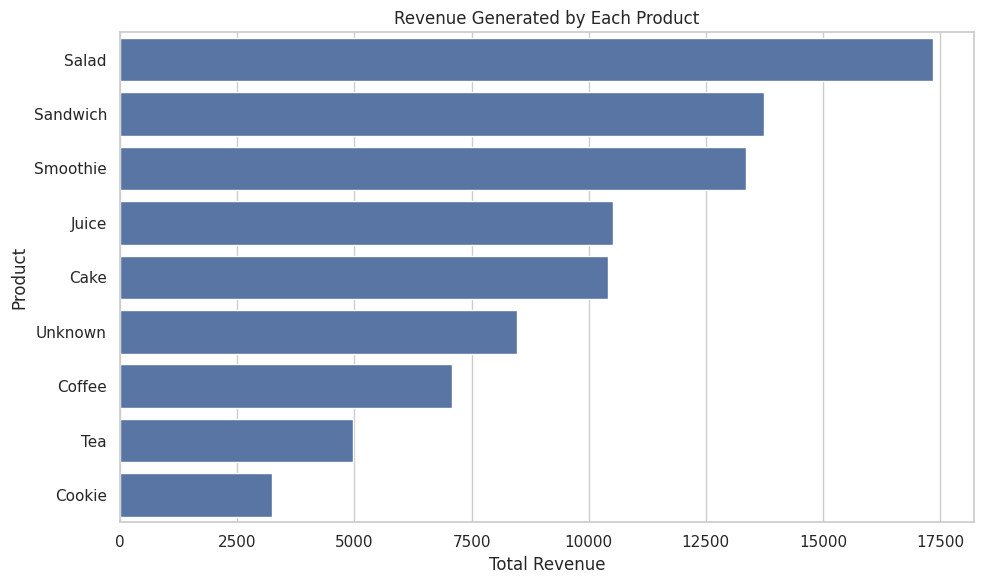

In [33]:

# STEP 6: Revenue generated by each product

product_revenue = (
    df.groupby('Item')['Total Spent']
    .sum()
    .sort_values(ascending=False)
)

print("REVENUE BY PRODUCT")
display(product_revenue)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=product_revenue.values,
    y=product_revenue.index
)

plt.title('Revenue Generated by Each Product')
plt.xlabel('Total Revenue')
plt.ylabel('Product')

plt.tight_layout()
plt.show()



1. PAYMENT METHOD ANALYSIS


,Transactions,Quantity_Sold,Total_Revenue,Revenue_Percentage
Payment Method,,,,
Unknown,3177,9563,27819.5,31.22
Credit Card,2272,6853,20458.0,22.96
Digital Wallet,2290,6939,20418.5,22.91
Cash,2258,6845,20415.5,22.91


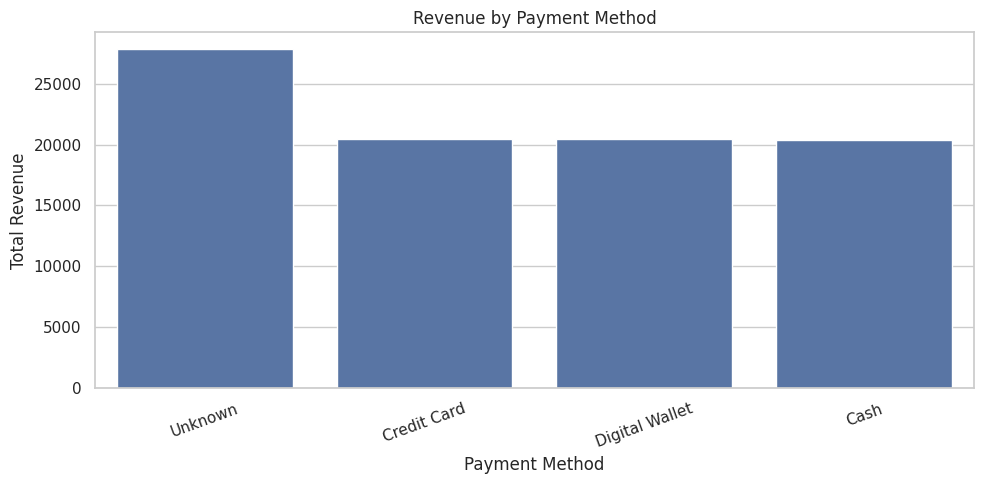

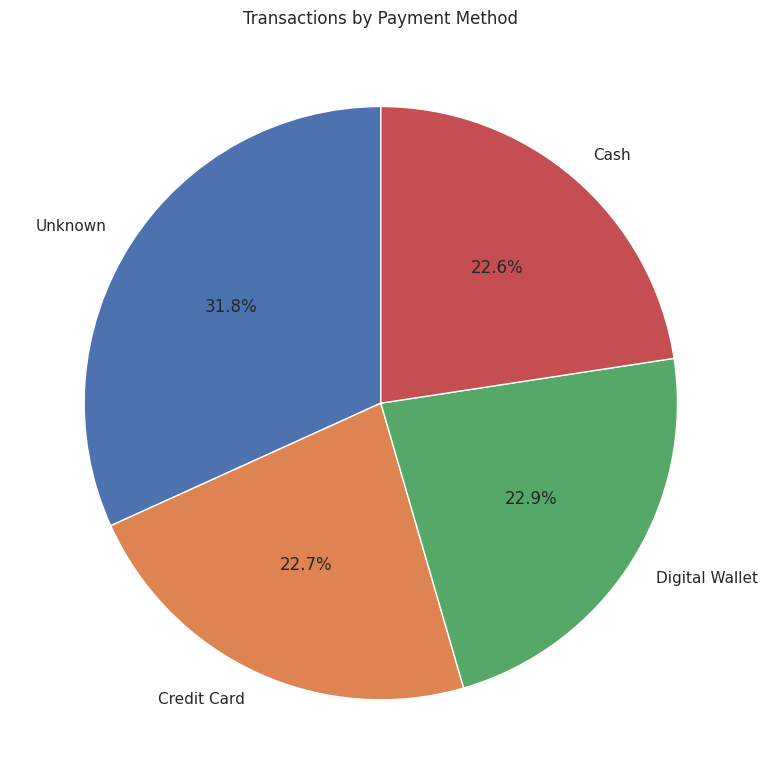


2. LOCATION COMPARISON


,Transactions,Quantity_Sold,Total_Revenue,Revenue_Percentage
Location,,,,
Unknown,3960,11909,35371.5,39.69
In-Store,3015,9141,27167.5,30.49
Takeaway,3022,9150,26572.5,29.82


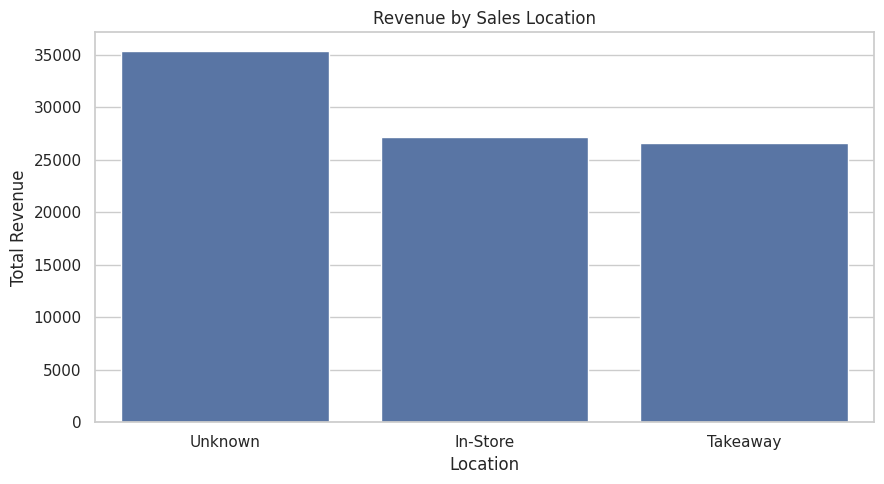

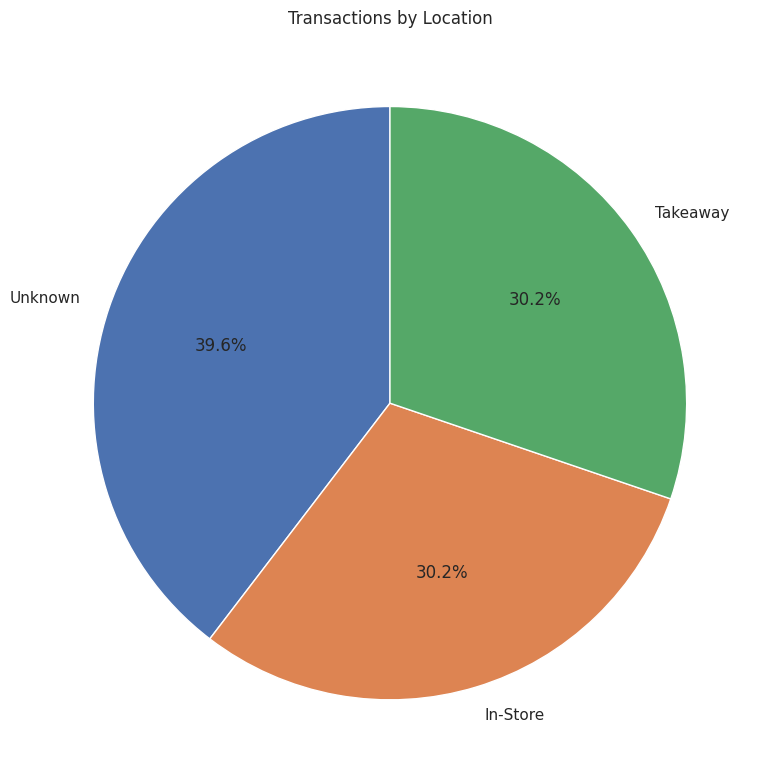


3. MONTHLY SALES TRENDS


,Transactions,Quantity_Sold,Total_Revenue
Month,,,
2023-01,1278,3877,11437.5
2023-02,727,2257,6648.0
2023-03,827,2471,7219.0
2023-04,774,2376,7187.0
2023-05,776,2336,6950.5
2023-06,818,2462,7355.0
2023-07,791,2339,6880.0
2023-08,802,2411,7093.5
2023-09,788,2360,6877.0


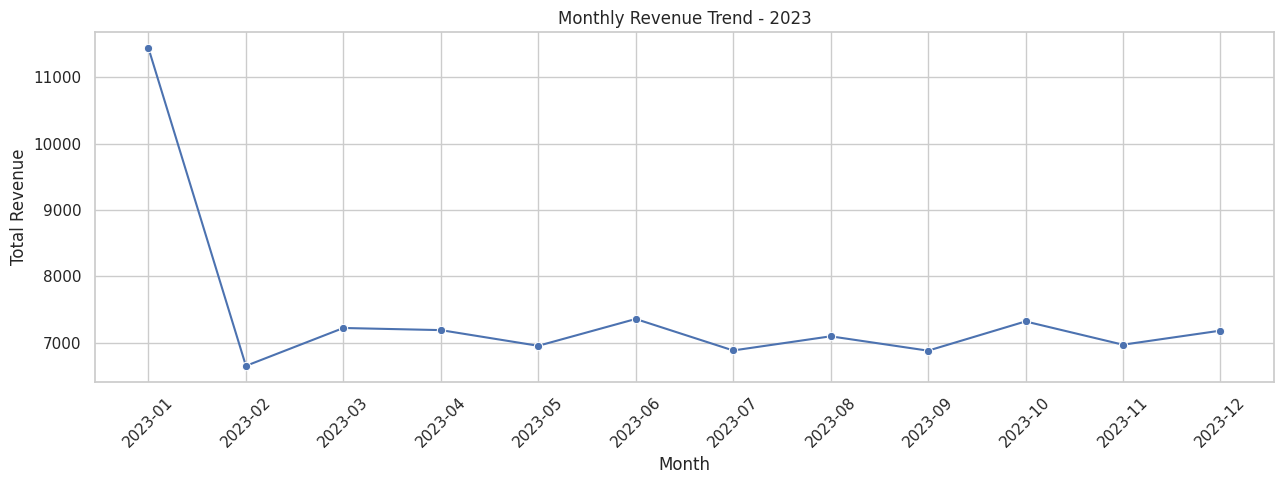

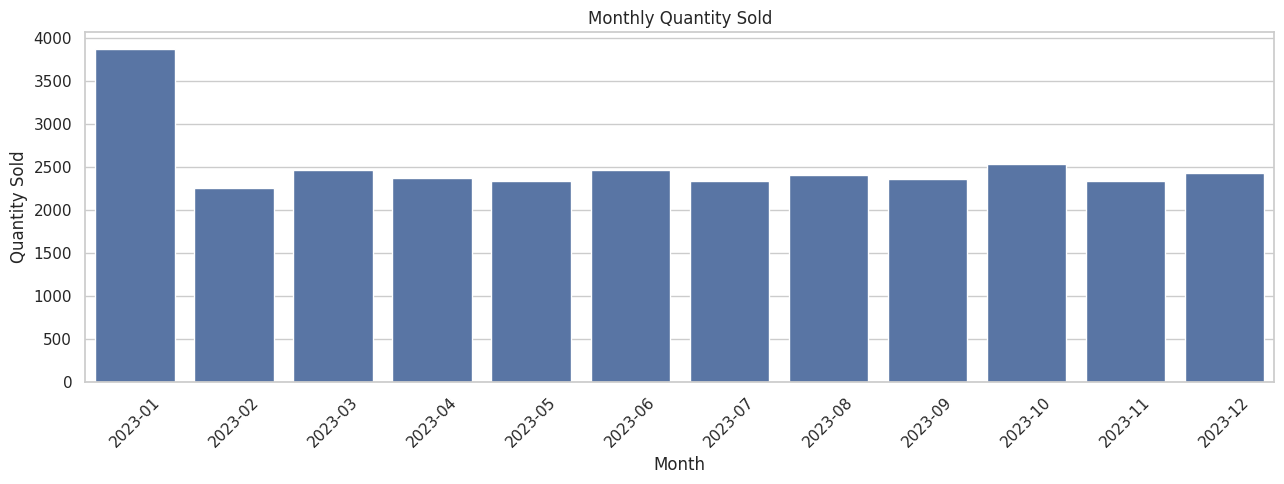


4. AUTOMATIC BUSINESS INSIGHTS
Highest Revenue Payment Method: Unknown
Highest Revenue Location: Unknown
Highest Revenue Month: 2023-01
Lowest Revenue Month: 2023-02

Highest Payment Method Revenue: 27819.5
Highest Location Revenue: 35371.5
Highest Monthly Revenue: 11437.5

ANALYSIS COMPLETED SUCCESSFULLY!


In [34]:

# ==========================================================
# CAFE SALES ANALYSIS
# PAYMENT METHOD, LOCATION & MONTHLY SALES TRENDS
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Make sure Transaction Date is in datetime format
df['Transaction Date'] = pd.to_datetime(
    df['Transaction Date'],
    errors='coerce'
)

# Create a copy for analysis
analysis_df = df.copy()

# ==========================================================
# 1. PAYMENT METHOD ANALYSIS
# ==========================================================

print("\n1. PAYMENT METHOD ANALYSIS")
print("=" * 50)

payment_analysis = (
    analysis_df.groupby('Payment Method')
    .agg(
        Transactions=('Transaction ID', 'nunique'),
        Quantity_Sold=('Quantity', 'sum'),
        Total_Revenue=('Total Spent', 'sum')
    )
    .sort_values('Total_Revenue', ascending=False)
)

payment_analysis['Revenue_Percentage'] = (
    payment_analysis['Total_Revenue'] /
    payment_analysis['Total_Revenue'].sum() * 100
).round(2)

display(payment_analysis.round(2))

# Payment method revenue chart
plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_analysis.reset_index(),
    x='Payment Method',
    y='Total_Revenue'
)

plt.title('Revenue by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Total Revenue')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Payment method transaction distribution
plt.figure(figsize=(8, 8))

plt.pie(
    payment_analysis['Transactions'],
    labels=payment_analysis.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Transactions by Payment Method')
plt.tight_layout()
plt.show()


# ==========================================================
# 2. LOCATION COMPARISON
# ==========================================================

print("\n2. LOCATION COMPARISON")
print("=" * 50)

location_analysis = (
    analysis_df.groupby('Location')
    .agg(
        Transactions=('Transaction ID', 'nunique'),
        Quantity_Sold=('Quantity', 'sum'),
        Total_Revenue=('Total Spent', 'sum')
    )
    .sort_values('Total_Revenue', ascending=False)
)

location_analysis['Revenue_Percentage'] = (
    location_analysis['Total_Revenue'] /
    location_analysis['Total_Revenue'].sum() * 100
).round(2)

display(location_analysis.round(2))

# Location revenue chart
plt.figure(figsize=(9, 5))

sns.barplot(
    data=location_analysis.reset_index(),
    x='Location',
    y='Total_Revenue'
)

plt.title('Revenue by Sales Location')
plt.xlabel('Location')
plt.ylabel('Total Revenue')
plt.tight_layout()
plt.show()

# Location transaction distribution
plt.figure(figsize=(8, 8))

plt.pie(
    location_analysis['Transactions'],
    labels=location_analysis.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Transactions by Location')
plt.tight_layout()
plt.show()


# ==========================================================
# 3. MONTHLY SALES TRENDS
# ==========================================================

print("\n3. MONTHLY SALES TRENDS")
print("=" * 50)

# Extract year and month
analysis_df['Month'] = (
    analysis_df['Transaction Date'].dt.to_period('M')
)

monthly_sales = (
    analysis_df.groupby('Month')
    .agg(
        Transactions=('Transaction ID', 'nunique'),
        Quantity_Sold=('Quantity', 'sum'),
        Total_Revenue=('Total Spent', 'sum')
    )
    .sort_index()
)

display(monthly_sales.round(2))

# Monthly revenue chart
plt.figure(figsize=(13, 5))

sns.lineplot(
    x=monthly_sales.index.astype(str),
    y=monthly_sales['Total_Revenue'],
    marker='o'
)

plt.title('Monthly Revenue Trend - 2023')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Monthly quantity sold chart
plt.figure(figsize=(13, 5))

sns.barplot(
    x=monthly_sales.index.astype(str),
    y=monthly_sales['Quantity_Sold']
)

plt.title('Monthly Quantity Sold')
plt.xlabel('Month')
plt.ylabel('Quantity Sold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ==========================================================
# 4. AUTOMATIC BUSINESS INSIGHTS
# ==========================================================

print("\n4. AUTOMATIC BUSINESS INSIGHTS")
print("=" * 50)

best_payment = payment_analysis['Total_Revenue'].idxmax()
best_location = location_analysis['Total_Revenue'].idxmax()
best_month = monthly_sales['Total_Revenue'].idxmax()
worst_month = monthly_sales['Total_Revenue'].idxmin()

print("Highest Revenue Payment Method:", best_payment)
print("Highest Revenue Location:", best_location)
print("Highest Revenue Month:", best_month)
print("Lowest Revenue Month:", worst_month)

print(
    "\nHighest Payment Method Revenue:",
    round(payment_analysis['Total_Revenue'].max(), 2)
)

print(
    "Highest Location Revenue:",
    round(location_analysis['Total_Revenue'].max(), 2)
)

print(
    "Highest Monthly Revenue:",
    round(monthly_sales['Total_Revenue'].max(), 2)
)

print("\nANALYSIS COMPLETED SUCCESSFULLY!")


In [35]:

# Export cleaned dataset for Power BI

# Make sure the date column is in date format
df['Transaction Date'] = pd.to_datetime(
    df['Transaction Date']
)

# Save as CSV
df.to_csv(
    'cafe_sales_cleaned.csv',
    index=False
)

# Download the file
from google.colab import files
files.download('cafe_sales_cleaned.csv')

print("Cleaned dataset exported successfully!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Cleaned dataset exported successfully!
